# Notebook 03 – Data Mining (luật kết hợp và phân cụm RFM) trên Superstore

## Mục 4.2. Ứng dụng Data Mining

**Mục tiêu:** trả lời **Câu hỏi 3** – khách hàng chia thành những nhóm nào, và những mặt hàng (Sub-Category) nào hay được mua cùng nhau?

- **Phần A1 – Luật kết hợp:** Apriori và FP-Growth trên giỏ hàng theo Order ID × Sub-Category.
- **Phần A2 – Phân cụm khách hàng:** K-Means trên điểm RFM (R, F, M từ 1 đến 5).

**Đầu vào:** `data/processed/superstore_clean.csv` (9.993 dòng) và `data/processed/rfm_customers.csv` (793 khách hàng), kết quả của Chương 3.

**Đầu ra:** 4 hình `figures/4_2_*.png` và các bảng `reports/4_2_*.csv`.

**Quy ước:** mọi bước ngẫu nhiên dùng `random_state = 42`; tiêu đề hình là một kết luận; không dùng biểu đồ hai trục tung.

**Cài thư viện nếu thiếu:** `pip install mlxtend scikit-learn`.

### Bước 0. Thiết lập môi trường

In [1]:
from pathlib import Path
import itertools
import textwrap
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown
import mlxtend
import sklearn
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
from sklearn.cluster import KMeans
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED, FIGURES, REPORTS = ROOT / "data" / "processed", ROOT / "figures", ROOT / "reports"
for p in (FIGURES, REPORTS):
    p.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
                     "axes.titleweight": "bold", "axes.titlesize": 11, "axes.labelsize": 10, "axes.grid.axis": "y"})
NEUTRAL, FOCUS, LOSS, INK = "#9AA5B1", "#1F6FB2", "#D62728", "#374151"

def vn(x, nd=0):
    # Số kiểu Việt Nam: dấu chấm ngăn nghìn, dấu phẩy thập phân, dấu trừ thật (−)
    return f"{x:,.{nd}f}".replace(",", "_").replace(".", ",").replace("_", ".").replace("-", "−")

def pct(x, nd=1): return vn(x, nd) + "%"

# Khổ hình: rộng tối đa 10 inch (giữ tỷ lệ) để khi đặt vào báo cáo (15 cm) chữ vẫn đọc được
def fs(w, h, tran=10.0):
    k = min(1.0, tran / w)
    return (w * k, h * k)

# Tiêu đề dài tự xuống dòng để không làm hình rộng ra
_sup = plt.Figure.suptitle
def _sup_gon(self, t, *a, **k):
    return _sup(self, "\n".join(textwrap.fill(p, 78) for p in str(t).split("\n")), *a, **k)
plt.Figure.suptitle = _sup_gon

def luu(fig, ten):
    duong_dan = FIGURES / f"4_2_{ten}.png"
    fig.savefig(duong_dan, dpi=200, facecolor="white", bbox_inches="tight")
    plt.show()
    print("Đã lưu hình:", duong_dan)

def nhan_xet(noi_dung): display(Markdown("**Nhận xét.** " + noi_dung))

print("mlxtend", mlxtend.__version__, "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

mlxtend 0.23.4 | scikit-learn 1.7.2 | pandas 2.3.3


## Phần A1. Khai phá luật kết hợp

### Bước 1. Tạo giỏ hàng nhị phân Order ID × Sub-Category
Mỗi dòng là một đơn hàng, mỗi cột là một Sub-Category; giá trị `True` nếu đơn có mặt hàng đó. Đây là "giỏ hàng" đầu vào của Apriori và FP-Growth.

In [2]:
df = pd.read_csv(PROCESSED / "superstore_clean.csv", encoding="utf-8-sig")
gio_hang = pd.crosstab(df["Order ID"], df["Sub-Category"]).gt(0)
so_don, so_mat_hang = gio_hang.shape
so_mh_moi_don = gio_hang.sum(axis=1)
n_hai_tro_len = int((so_mh_moi_don >= 2).sum())
tb_mh = so_mh_moi_don.mean()
sup_mh = gio_hang.mean().sort_values(ascending=False)

print(f"Giỏ hàng: {so_don:,} đơn × {so_mat_hang} Sub-Category")
print(f"Số đơn có từ 2 Sub-Category trở lên: {n_hai_tro_len:,} ({n_hai_tro_len / so_don * 100:.1f}%)")
print(f"Số Sub-Category trung bình mỗi đơn: {tb_mh:.2f}")
top6 = pd.DataFrame({"Support (%)": (sup_mh.head(6) * 100).round(1), "Số đơn": (sup_mh.head(6) * so_don).round().astype(int)})
display(top6)
nhan_xet(f"Chỉ {pct(n_hai_tro_len / so_don * 100)} số đơn ({vn(n_hai_tro_len)}/{vn(so_don)}) có từ hai Sub-Category trở lên, "
         f"trung bình {vn(tb_mh, 2)} Sub-Category mỗi đơn. Ba mặt hàng phổ biến nhất là {sup_mh.index[0]} ({pct(sup_mh.iloc[0] * 100)}), "
         f"{sup_mh.index[1]} ({pct(sup_mh.iloc[1] * 100)}) và {sup_mh.index[2]} ({pct(sup_mh.iloc[2] * 100)}); "
         f"vì giỏ hàng nhỏ nên các cặp mặt hàng đi cùng nhau có support thấp.")

Giỏ hàng: 5,009 đơn × 17 Sub-Category
Số đơn có từ 2 Sub-Category trở lên: 2,346 (46.8%)
Số Sub-Category trung bình mỗi đơn: 1.83


,Support (%),Số đơn
Sub-Category,,
Binders,26.3,1316
Paper,23.8,1191
Furnishings,17.5,877
Phones,16.3,814
Storage,15.5,777
Art,14.6,731


**Nhận xét.** Chỉ 46,8% số đơn (2.346/5.009) có từ hai Sub-Category trở lên, trung bình 1,83 Sub-Category mỗi đơn. Ba mặt hàng phổ biến nhất là Binders (26,3%), Paper (23,8%) và Furnishings (17,5%); vì giỏ hàng nhỏ nên các cặp mặt hàng đi cùng nhau có support thấp.

### Bước 2. Apriori và FP-Growth với 5 ngưỡng min_support
Mỗi ngưỡng: số tập phổ biến, số tập có từ 2 phần tử, kiểm tra hai thuật toán cho **cùng kết quả**, số luật có lift > 1 và thời gian chạy (trung vị của 5 lần chạy).

In [3]:
NGUONG = [0.03, 0.02, 0.01, 0.005, 0.003]

def do_thoi_gian(ham, min_support, lan=5):
    t = []
    for _ in range(lan):
        t0 = time.perf_counter()
        ham(gio_hang, min_support=min_support, use_colnames=True)
        t.append((time.perf_counter() - t0) * 1000)
    return float(np.median(t))

def dict_tap(ket_qua):
    return {frozenset(i): round(float(v), 12) for i, v in zip(ket_qua["itemsets"], ket_qua["support"])}

dong = []
for s in NGUONG:
    ap = apriori(gio_hang, min_support=s, use_colnames=True)
    fp = fpgrowth(gio_hang, min_support=s, use_colnames=True)
    giong = dict_tap(ap) == dict_tap(fp)
    n_tap = len(ap)
    n_tap_2 = int((ap["itemsets"].apply(len) >= 2).sum())
    luat = association_rules(ap, num_itemsets=so_don, metric="lift", min_threshold=1)
    n_luat = int((luat["lift"] > 1).sum())
    dong.append({"Ngưỡng support (%)": s * 100, "Số tập phổ biến": n_tap, "Số tập ≥ 2 phần tử": n_tap_2,
                 "Apriori = FP-Growth": giong, "Số luật (lift > 1)": n_luat,
                 "Apriori (ms)": do_thoi_gian(apriori, s), "FP-Growth (ms)": do_thoi_gian(fpgrowth, s)})
nguong_bang = pd.DataFrame(dong)
nguong_bang["FP-Growth / Apriori (lần)"] = nguong_bang["FP-Growth (ms)"] / nguong_bang["Apriori (ms)"]
nguong_bang.round(2).to_csv(REPORTS / "4_2_support_thresholds.csv", index=False, encoding="utf-8-sig")
display(nguong_bang.round(2))

hai_giong = bool(nguong_bang["Apriori = FP-Growth"].all())
ap_nhanh = bool((nguong_bang["Apriori (ms)"] < nguong_bang["FP-Growth (ms)"]).all())
nhan_xet(f"Hai thuật toán cho {'cùng' if hai_giong else 'KHÁC'} tập phổ biến ở cả 5 ngưỡng. Số luật lift > 1 tăng từ "
         f"{vn(nguong_bang.iloc[0]['Số luật (lift > 1)'])} (ngưỡng 3%) lên {vn(nguong_bang.iloc[-1]['Số luật (lift > 1)'])} (ngưỡng 0,3%). "
         f"{'Apriori nhanh hơn FP-Growth ở mọi ngưỡng' if ap_nhanh else 'Apriori không luôn nhanh hơn FP-Growth'} "
         f"(ở ngưỡng 0,3%: {vn(nguong_bang.iloc[-1]['Apriori (ms)'], 1)} ms so với {vn(nguong_bang.iloc[-1]['FP-Growth (ms)'], 1)} ms).")

,Ngưỡng support (%),Số tập phổ biến,Số tập ≥ 2 phần tử,Apriori = FP-Growth,Số luật (lift > 1),Apriori (ms),FP-Growth (ms),FP-Growth / Apriori (lần)
0,3.0,24,9,True,0,1.00,48.31,48.38
1,2.0,38,22,True,10,1.06,102.93,97.36
2,1.0,68,51,True,42,1.79,228.86,127.58
3,0.5,138,121,True,274,3.06,541.32,176.92
4,0.3,204,187,True,582,3.90,817.63,209.51


**Nhận xét.** Hai thuật toán cho cùng tập phổ biến ở cả 5 ngưỡng. Số luật lift > 1 tăng từ 0 (ngưỡng 3%) lên 582 (ngưỡng 0,3%). Apriori nhanh hơn FP-Growth ở mọi ngưỡng (ở ngưỡng 0,3%: 3,9 ms so với 817,6 ms).

### Hình 4_2_1. Số luật và thời gian chạy theo ngưỡng support
Hai biểu đồ đặt cạnh nhau (không dùng hai trục tung): bên trái là số luật, bên phải là thời gian chạy (thang log vì hai thuật toán chênh nhau hàng chục lần).

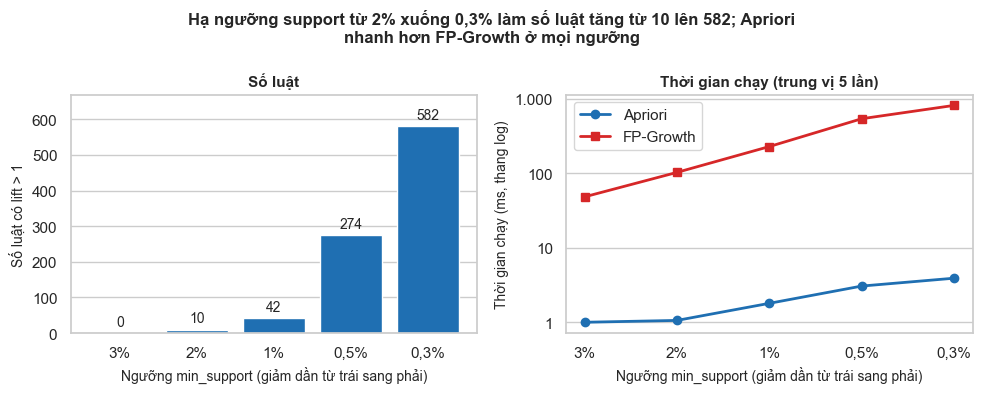

Đã lưu hình: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/figures/4_2_1_rules_by_support.png


In [4]:
nhan_nguong = [pct(v, 0 if float(v).is_integer() else 1) for v in nguong_bang["Ngưỡng support (%)"]]
so_luat = nguong_bang["Số luật (lift > 1)"].to_numpy()

fig, (a1, a2) = plt.subplots(1, 2, figsize=fs(13, 5.2))
x = np.arange(len(nhan_nguong))
a1.bar(x, so_luat, color=[NEUTRAL if v == 0 else FOCUS for v in so_luat])
for xi, v in zip(x, so_luat):
    a1.annotate(vn(v), (xi, v), ha="center", va="bottom", fontsize=10, xytext=(0, 3), textcoords="offset points")
a1.set_xticks(x); a1.set_xticklabels(nhan_nguong)
a1.set_xlabel("Ngưỡng min_support (giảm dần từ trái sang phải)"); a1.set_ylabel("Số luật có lift > 1")
a1.set_ylim(0, so_luat.max() * 1.15); a1.set_title("Số luật")

a2.plot(x, nguong_bang["Apriori (ms)"], marker="o", color=FOCUS, lw=2, label="Apriori")
a2.plot(x, nguong_bang["FP-Growth (ms)"], marker="s", color=LOSS, lw=2, label="FP-Growth")
a2.set_yscale("log")
a2.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: vn(v, 0 if v >= 1 else 1)))
a2.set_xticks(x); a2.set_xticklabels(nhan_nguong)
a2.set_xlabel("Ngưỡng min_support (giảm dần từ trái sang phải)"); a2.set_ylabel("Thời gian chạy (ms, thang log)")
a2.legend(loc="upper left"); a2.set_title("Thời gian chạy (trung vị 5 lần)")
tieu_de = (f"Hạ ngưỡng support từ 2% xuống 0,3% làm số luật tăng từ {vn(so_luat[1])} lên {vn(so_luat[-1])}; "
           + ("Apriori nhanh hơn FP-Growth ở mọi ngưỡng" if ap_nhanh else "Apriori và FP-Growth có tốc độ khác nhau tùy ngưỡng"))
fig.suptitle(tieu_de, fontsize=12, fontweight="bold")
fig.tight_layout()
luu(fig, "1_rules_by_support")

### Bước 3. Các luật chi tiết ở ngưỡng 2%, 1% và 0,5%
Luật được sắp theo lift giảm dần. Mỗi luật xuất hiện hai lần (X → Y và Y → X) vì lift đối xứng; confidence thì khác nhau.

In [5]:
def lay_luat(min_support):
    ap = apriori(gio_hang, min_support=min_support, use_colnames=True)
    r = association_rules(ap, num_itemsets=so_don, metric="lift", min_threshold=1)
    r = r[r["lift"] > 1].copy()
    r["antecedents"] = r["antecedents"].apply(lambda t: ", ".join(sorted(t)))
    r["consequents"] = r["consequents"].apply(lambda t: ", ".join(sorted(t)))
    r["so_don"] = (r["support"] * so_don).round().astype(int)
    cot = ["antecedents", "consequents", "support", "confidence", "lift", "leverage", "conviction", "so_don"]
    r["lift_lam_tron"] = r["lift"].round(9)     # tránh sai số dấu phẩy động làm đảo thứ tự hai chiều của cùng một luật
    return r.sort_values(["lift_lam_tron", "confidence"], ascending=False).reset_index(drop=True)[cot]

def tap(t):
    return "{" + t + "}" if "," in t else t

def hien_thi(r, n=None):
    t = r.head(n) if n else r
    out = pd.DataFrame({"Tiền đề (X)": t["antecedents"], "Hệ quả (Y)": t["consequents"], "Support (%)": (t["support"] * 100).round(2),
                        "Confidence (%)": (t["confidence"] * 100).round(1), "Lift": t["lift"].round(3), "Số đơn": t["so_don"]})
    display(out)

luat_2, luat_1, luat_05 = lay_luat(0.02), lay_luat(0.01), lay_luat(0.005)
print(f"Ngưỡng 2%: {len(luat_2)} luật lift > 1"); hien_thi(luat_2)
print(f"Ngưỡng 1%: {len(luat_1)} luật lift > 1"); hien_thi(luat_1)
print(f"Ngưỡng 0,5%: {len(luat_05)} luật lift > 1 (10 luật lift cao nhất)"); hien_thi(luat_05, 10)

# Lưu toàn bộ luật ở ngưỡng 0,5%; thêm cột cho biết ngưỡng cao nhất mà luật còn xuất hiện
def nguong_xuat_hien(sup):
    for s in (0.02, 0.01, 0.005):
        if sup >= s - 1e-12: return s * 100
    return np.nan
luat_luu = luat_05.copy()
luat_luu["nguong_cao_nhat_con_xuat_hien (%)"] = luat_luu["support"].apply(nguong_xuat_hien)
luat_luu.to_csv(REPORTS / "4_2_rules.csv", index=False, encoding="utf-8-sig")

r0 = luat_2.iloc[0]
nhan_xet(f"Ở ngưỡng 2%, luật mạnh nhất là {r0['antecedents']} → {r0['consequents']} (support {pct(r0['support'] * 100, 2)}, confidence "
         f"{pct(r0['confidence'] * 100)}, lift {vn(r0['lift'], 2)}); toàn bộ {len(luat_2)} luật đều có lift không quá {vn(luat_2['lift'].max(), 2)}. "
         f"Ở ngưỡng 1%, lift cao nhất là {vn(luat_1['lift'].max(), 2)}. Ở ngưỡng 0,5%, luật {tap(luat_05.iloc[0]['antecedents'])} → {tap(luat_05.iloc[0]['consequents'])} "
         f"có confidence {pct(luat_05.iloc[0]['confidence'] * 100)} và lift {vn(luat_05.iloc[0]['lift'], 2)} nhưng chỉ dựa trên {luat_05.iloc[0]['so_don']} đơn.")

Ngưỡng 2%: 10 luật lift > 1


,Tiền đề (X),Hệ quả (Y),Support (%),Confidence (%),Lift,Số đơn
0,Appliances,Binders,2.60,28.8,1.097,130
1,Binders,Appliances,2.60,9.9,1.097,130
2,Art,Phones,2.48,17.0,1.044,124
3,Phones,Art,2.48,15.2,1.044,124
4,Phones,Furnishings,2.95,18.2,1.038,148
5,Furnishings,Phones,2.95,16.9,1.038,148
6,Appliances,Paper,2.18,24.2,1.016,109
7,Paper,Appliances,2.18,9.2,1.016,109
8,Storage,Furnishings,2.76,17.8,1.014,138
9,Furnishings,Storage,2.76,15.7,1.014,138


Ngưỡng 1%: 42 luật lift > 1


,Tiền đề (X),Hệ quả (Y),Support (%),Confidence (%),Lift,Số đơn
0,"Binders, Paper",Storage,1.06,19.3,1.242,53
1,Storage,"Binders, Paper",1.06,6.8,1.242,53
2,"Binders, Paper",Phones,1.08,19.6,1.208,54
3,Phones,"Binders, Paper",1.08,6.6,1.208,54
4,"Paper, Phones",Binders,1.08,30.9,1.174,54
5,Binders,"Paper, Phones",1.08,4.1,1.174,54
6,Fasteners,Paper,1.18,27.4,1.154,59
7,Paper,Fasteners,1.18,5.0,1.154,59
8,"Binders, Phones",Paper,1.08,27.1,1.141,54
9,Paper,"Binders, Phones",1.08,4.5,1.141,54


Ngưỡng 0,5%: 274 luật lift > 1 (10 luật lift cao nhất)


,Tiền đề (X),Hệ quả (Y),Support (%),Confidence (%),Lift,Số đơn
0,"Appliances, Storage",Binders,0.60,53.6,2.039,30
1,Binders,"Appliances, Storage",0.60,2.3,2.039,30
2,"Chairs, Phones",Art,0.52,29.2,2.002,26
3,Art,"Chairs, Phones",0.52,3.6,2.002,26
4,"Art, Chairs",Phones,0.52,31.7,1.951,26
5,Phones,"Art, Chairs",0.52,3.2,1.951,26
6,"Binders, Furnishings",Appliances,0.68,17.2,1.907,34
7,Appliances,"Binders, Furnishings",0.68,7.5,1.907,34
8,"Phones, Storage",Furnishings,0.76,32.5,1.855,38
9,Furnishings,"Phones, Storage",0.76,4.3,1.855,38


**Nhận xét.** Ở ngưỡng 2%, luật mạnh nhất là Appliances → Binders (support 2,60%, confidence 28,8%, lift 1,10); toàn bộ 10 luật đều có lift không quá 1,10. Ở ngưỡng 1%, lift cao nhất là 1,24. Ở ngưỡng 0,5%, luật {Appliances, Storage} → Binders có confidence 53,6% và lift 2,04 nhưng chỉ dựa trên 30 đơn.

### Hình 4_2_2. Support, confidence và lift của các luật ở ngưỡng 0,5%

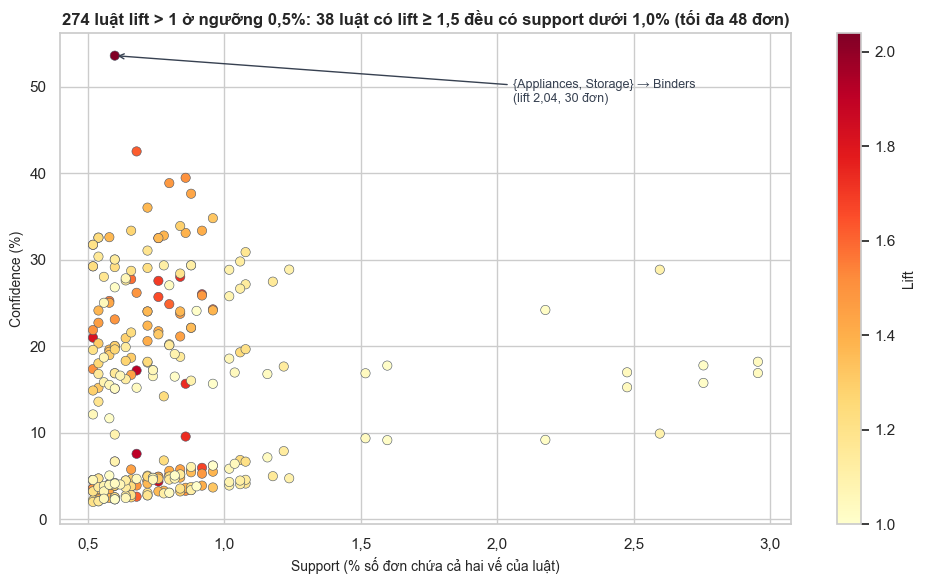

Đã lưu hình: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/figures/4_2_2_rules_scatter.png


**Nhận xét.** 99,3% số luật có confidence dưới 40%. Các luật có lift từ 1,5 trở lên (38 luật) đều có support thấp, tối đa 48 đơn trong 5.009 đơn; luật vừa có support cao vừa có lift cao không tồn tại trong dữ liệu này.

In [6]:
n_l15 = int((luat_05["lift"] >= 1.5).sum())
sup_l15_max = luat_05.loc[luat_05["lift"] >= 1.5, "support"].max() * 100
don_l15_max = luat_05.loc[luat_05["lift"] >= 1.5, "so_don"].max()
ti_le_conf40 = (luat_05["confidence"] < 0.4).mean() * 100

fig, ax = plt.subplots(figsize=fs(10, 6))
sc = ax.scatter(luat_05["support"] * 100, luat_05["confidence"] * 100, c=luat_05["lift"], cmap="YlOrRd", s=45,
                edgecolor="#4B5563", linewidth=0.4, vmin=1, vmax=luat_05["lift"].max())
cb = fig.colorbar(sc, ax=ax); cb.set_label("Lift")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: vn(v, 1)))
ax.set_xlabel("Support (% số đơn chứa cả hai vế của luật)"); ax.set_ylabel("Confidence (%)")
ax.grid(axis="x", visible=True)
top = luat_05.iloc[0]
ax.annotate(f"{tap(top['antecedents'])} → {tap(top['consequents'])}\n(lift {vn(top['lift'], 2)}, {top['so_don']} đơn)",
            (top["support"] * 100, top["confidence"] * 100), xytext=(0.62, 0.86), textcoords="axes fraction", ha="left", fontsize=9, color=INK,
            arrowprops=dict(arrowstyle="->", color=INK))
ax.set_title(f"{vn(len(luat_05))} luật lift > 1 ở ngưỡng 0,5%: {n_l15} luật có lift ≥ 1,5 đều có support dưới {vn(np.ceil(sup_l15_max * 10) / 10, 1)}% (tối đa {vn(don_l15_max)} đơn)",
             fontsize=12)
fig.tight_layout()
luu(fig, "2_rules_scatter")
nhan_xet(f"{pct(ti_le_conf40)} số luật có confidence dưới 40%. Các luật có lift từ 1,5 trở lên ({n_l15} luật) đều có support thấp, tối đa {vn(don_l15_max)} đơn "
         f"trong {vn(so_don)} đơn; luật vừa có support cao vừa có lift cao không tồn tại trong dữ liệu này.")

### Bước 4. Kiểm định chi-square độc lập cho 3 cặp mặt hàng có lift cao nhất ở ngưỡng 2%
Với mỗi cặp (A, B) lập bảng chéo 2×2 "đơn có A × đơn có B" trên 5.009 đơn. Giả thuyết H0: việc mua A và mua B độc lập với nhau. Dùng `scipy.stats.chi2_contingency` (có hiệu chỉnh Yates với bảng 2×2), mức ý nghĩa α = 0,05.

In [7]:
cap_da_xet, cap_top = set(), []
for _, r in luat_2.iterrows():
    cap = tuple(sorted([r["antecedents"], r["consequents"]]))
    if cap not in cap_da_xet:
        cap_da_xet.add(cap); cap_top.append((cap, r["lift"]))
    if len(cap_top) == 3: break

dong = []
for (a, b), lift in cap_top:
    bang = pd.crosstab(gio_hang[a], gio_hang[b])
    chi2, p, dof, ky_vong = stats.chi2_contingency(bang)
    n_a, n_b, n_ab = int(gio_hang[a].sum()), int(gio_hang[b].sum()), int((gio_hang[a] & gio_hang[b]).sum())
    dong.append({"Cặp mặt hàng": f"{a} – {b}", "Lift": round(lift, 3), "Số đơn chứa cả hai": n_ab,
                 "Số đơn kỳ vọng nếu độc lập": round(n_a * n_b / so_don, 1), "χ²": round(chi2, 2), "p-value": round(p, 3),
                 "Kết luận (α = 0,05)": "Có ý nghĩa" if p < 0.05 else "Không có ý nghĩa"})
chi_bang = pd.DataFrame(dong)
chi_bang.to_csv(REPORTS / "4_2_chi2_pairs.csv", index=False, encoding="utf-8-sig")
display(chi_bang)
nhan_xet("Cả ba cặp đều có p-value lớn hơn 0,05 (" + ", ".join(vn(v, 2) for v in chi_bang["p-value"]) + "), nghĩa là không đủ bằng chứng để bác bỏ giả thuyết "
         "hai mặt hàng được mua độc lập. Số đơn thực tế chứa cả hai chỉ hơn số đơn kỳ vọng nếu độc lập từ "
         + vn((chi_bang["Số đơn chứa cả hai"] - chi_bang["Số đơn kỳ vọng nếu độc lập"]).min(), 1) + " đến "
         + vn((chi_bang["Số đơn chứa cả hai"] - chi_bang["Số đơn kỳ vọng nếu độc lập"]).max(), 1) + " đơn.")

,Cặp mặt hàng,Lift,Số đơn chứa cả hai,Số đơn kỳ vọng nếu độc lập,χ²,p-value,"Kết luận (α = 0,05)"
0,Appliances – Binders,1.097,130,118.5,1.52,0.217,Không có ý nghĩa
1,Art – Phones,1.044,124,118.8,0.26,0.610,Không có ý nghĩa
2,Furnishings – Phones,1.038,148,142.5,0.25,0.616,Không có ý nghĩa


**Nhận xét.** Cả ba cặp đều có p-value lớn hơn 0,05 (0,22, 0,61, 0,62), nghĩa là không đủ bằng chứng để bác bỏ giả thuyết hai mặt hàng được mua độc lập. Số đơn thực tế chứa cả hai chỉ hơn số đơn kỳ vọng nếu độc lập từ 5,2 đến 11,5 đơn.

### Bước 5. Kết luận cho phần luật kết hợp

In [8]:
lift_max_2, lift_max_1 = luat_2["lift"].max(), luat_1["lift"].max()
display(Markdown(f'''
**Luật có mạnh không?** Không. Ở các ngưỡng có support đủ lớn (từ 1% trở lên) lift chỉ đạt tối đa {vn(lift_max_1, 2)}, tức xác suất mua kèm chỉ cao hơn mức kỳ vọng khi hai mặt hàng độc lập
khoảng {vn((lift_max_1 - 1) * 100)}%. Lift gần 2 chỉ xuất hiện ở ngưỡng 0,5% và dựa trên chưa đến 40 đơn.

**Có ý nghĩa thống kê không?** Không. Ba cặp có lift cao nhất ở ngưỡng 2% đều có p-value từ {vn(chi_bang["p-value"].min(), 2)} trở lên (> 0,05).

**Có đủ cơ sở để đề xuất bán kèm (cross-sell) không?** Chưa. Dữ liệu này không cho thấy mối liên hệ mua kèm đáng tin cậy ở mức Sub-Category; nếu muốn thiết kế combo cần thử nghiệm A/B hoặc phân tích ở mức sản phẩm cụ thể.

**Vì sao FP-Growth không nhanh hơn Apriori ở đây?** Dữ liệu chỉ có {so_mat_hang} mặt hàng nên số tập ứng viên của Apriori rất nhỏ và
được xử lý bằng phép tính ma trận; trong khi FP-Growth phải dựng cây FP-tree và khai phá đệ quy, chi phí này không được bù lại. Lợi thế của FP-Growth thể hiện khi số mặt hàng
và số giao dịch lớn, lúc Apriori phải sinh và kiểm tra rất nhiều tập ứng viên qua nhiều lượt quét dữ liệu.
'''))


**Luật có mạnh không?** Không. Ở các ngưỡng có support đủ lớn (từ 1% trở lên) lift chỉ đạt tối đa 1,24, tức xác suất mua kèm chỉ cao hơn mức kỳ vọng khi hai mặt hàng độc lập
khoảng 24%. Lift gần 2 chỉ xuất hiện ở ngưỡng 0,5% và dựa trên chưa đến 40 đơn.

**Có ý nghĩa thống kê không?** Không. Ba cặp có lift cao nhất ở ngưỡng 2% đều có p-value từ 0,22 trở lên (> 0,05).

**Có đủ cơ sở để đề xuất bán kèm (cross-sell) không?** Chưa. Dữ liệu này không cho thấy mối liên hệ mua kèm đáng tin cậy ở mức Sub-Category; nếu muốn thiết kế combo cần thử nghiệm A/B hoặc phân tích ở mức sản phẩm cụ thể.

**Vì sao FP-Growth không nhanh hơn Apriori ở đây?** Dữ liệu chỉ có 17 mặt hàng nên số tập ứng viên của Apriori rất nhỏ và
được xử lý bằng phép tính ma trận; trong khi FP-Growth phải dựng cây FP-tree và khai phá đệ quy, chi phí này không được bù lại. Lợi thế của FP-Growth thể hiện khi số mặt hàng
và số giao dịch lớn, lúc Apriori phải sinh và kiểm tra rất nhiều tập ứng viên qua nhiều lượt quét dữ liệu.


## Phần A2. Phân cụm khách hàng theo RFM

### Bước 6. Dữ liệu RFM và chuẩn hóa
Dùng ba cột điểm R, F, M (1–5) của 793 khách hàng và chuẩn hóa bằng `StandardScaler` để ba chiều có cùng thang đo.

In [9]:
rfm = pd.read_csv(PROCESSED / "rfm_customers.csv", encoding="utf-8-sig")
kh = pd.read_csv(PROCESSED / "customers_level.csv", encoding="utf-8-sig")
assert len(rfm) == 793 and rfm["Customer ID"].is_unique
X_rfm = StandardScaler().fit_transform(rfm[["R_score", "F_score", "M_score"]])
display(rfm[["R_score", "F_score", "M_score"]].describe().round(2))
nhan_xet(f"Ba điểm đều nằm trong khoảng 1–5 với trung bình R = {vn(rfm['R_score'].mean(), 2)}, F = {vn(rfm['F_score'].mean(), 2)}, "
         f"M = {vn(rfm['M_score'].mean(), 2)}; vì mỗi điểm chia theo năm nhóm gần bằng nhau nên trung bình xấp xỉ 3.")

,R_score,F_score,M_score
count,793.00,793.00,793.00
mean,3.01,3.00,3.00
std,1.42,1.42,1.42
min,1.00,1.00,1.00
25%,2.00,2.00,2.00
50%,3.00,3.00,3.00
75%,4.00,4.00,4.00
max,5.00,5.00,5.00


**Nhận xét.** Ba điểm đều nằm trong khoảng 1–5 với trung bình R = 3,01, F = 3,00, M = 3,00; vì mỗi điểm chia theo năm nhóm gần bằng nhau nên trung bình xấp xỉ 3.

### Bước 7. Chọn số cụm k: Elbow, Silhouette, Davies–Bouldin
K-Means với `n_init = 20`, k = 2…10. **Silhouette** càng cao càng tốt (khoảng −1 đến 1); **Davies–Bouldin** càng thấp càng tốt; **inertia** là tổng bình phương khoảng cách tới tâm cụm (tìm điểm "gãy" của đường Elbow).

In [10]:
dong = []
for k in range(2, 11):
    km_k = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X_rfm)
    dong.append({"k": k, "Inertia": km_k.inertia_, "Silhouette": silhouette_score(X_rfm, km_k.labels_),
                 "Davies-Bouldin": davies_bouldin_score(X_rfm, km_k.labels_)})
chon_k = pd.DataFrame(dong)
chon_k["Inertia giảm so với k trước (%)"] = -chon_k["Inertia"].pct_change() * 100
chon_k.round(6).to_csv(REPORTS / "4_2_kmeans_k_selection.csv", index=False, encoding="utf-8-sig")
display(chon_k.round(3))
sil = chon_k.set_index("k")["Silhouette"]
nhan_xet(f"Silhouette chỉ dao động trong khoảng {vn(sil.min(), 2)}–{vn(sil.max(), 2)} ở mọi k, cao nhất ở k = 2 ({vn(sil.loc[2], 3)}) và thấp nhất ở k = 4 ({vn(sil.loc[4], 3)}): "
         f"cấu trúc cụm ở mức trung bình, chưa rõ nét. Inertia giảm chậm lại sau k = 4 (từ {vn(chon_k.set_index('k').loc[4, 'Inertia giảm so với k trước (%)'], 1)}% xuống "
         f"{vn(chon_k.set_index('k').loc[5, 'Inertia giảm so với k trước (%)'], 1)}%).")

,k,Inertia,Silhouette,Davies-Bouldin,Inertia giảm so với k trước (%)
0,2,1382.641,0.368,1.102,NaN
1,3,1065.927,0.332,1.131,22.906
2,4,837.953,0.323,1.090,21.387
3,5,717.525,0.324,1.076,14.372
4,6,612.343,0.336,1.043,14.659
5,7,537.000,0.341,0.980,12.304
6,8,476.960,0.344,0.983,11.181
7,9,433.264,0.348,1.005,9.161
8,10,405.897,0.344,1.054,6.316


**Nhận xét.** Silhouette chỉ dao động trong khoảng 0,32–0,37 ở mọi k, cao nhất ở k = 2 (0,368) và thấp nhất ở k = 4 (0,323): cấu trúc cụm ở mức trung bình, chưa rõ nét. Inertia giảm chậm lại sau k = 4 (từ 21,4% xuống 14,4%).

### Hình 4_2_3. Elbow và Silhouette theo k

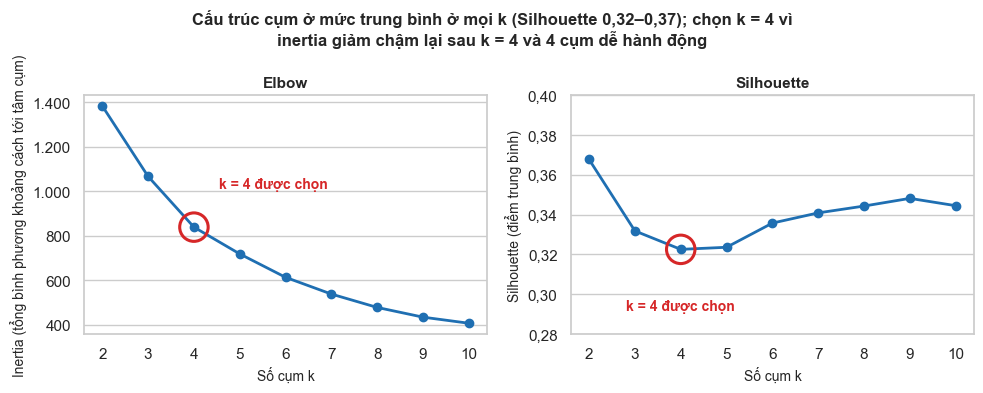

Đã lưu hình: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/figures/4_2_3_kmeans_k_selection.png


In [11]:
K = 4
fig, (a1, a2) = plt.subplots(1, 2, figsize=fs(13, 5.2))
a1.plot(chon_k["k"], chon_k["Inertia"], marker="o", color=FOCUS, lw=2)
a1.set_xlabel("Số cụm k"); a1.set_ylabel("Inertia (tổng bình phương khoảng cách tới tâm cụm)")
a1.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: vn(v))); a1.set_title("Elbow"); a1.set_xticks(chon_k["k"])
a2.plot(chon_k["k"], chon_k["Silhouette"], marker="o", color=FOCUS, lw=2)
a2.set_xlabel("Số cụm k"); a2.set_ylabel("Silhouette (điểm trung bình)"); a2.set_xticks(chon_k["k"])
a2.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: vn(v, 2))); a2.set_title("Silhouette"); a2.set_ylim(0.28, 0.40)
for ax, cot in ((a1, "Inertia"), (a2, "Silhouette")):
    gia_tri = chon_k.loc[chon_k["k"] == K, cot].iloc[0]
    ax.scatter([K], [gia_tri], s=420, facecolor="none", edgecolor=LOSS, linewidth=2.2, zorder=5)
    ax.annotate("k = 4 được chọn", (K, gia_tri), xytext=((18, 28) if cot == "Inertia" else (0, -44)), textcoords="offset points", color=LOSS, fontsize=10,
                fontweight="bold", ha=("left" if cot == "Inertia" else "center"))
fig.suptitle(f"Cấu trúc cụm ở mức trung bình ở mọi k (Silhouette {vn(sil.min(), 2)}–{vn(sil.max(), 2)}); chọn k = 4 vì inertia giảm chậm lại sau k = 4 và 4 cụm dễ hành động",
             fontsize=12, fontweight="bold")
fig.tight_layout()
luu(fig, "3_kmeans_k_selection")

### Bước 8. Biện luận chọn k = 4

In [12]:
db = chon_k.set_index("k")["Davies-Bouldin"]
display(Markdown(f'''
**Lý do chọn k = 4** (nêu cả điểm yếu):

- **Silhouette không ủng hộ mạnh k = 4:** k = 4 có Silhouette thấp nhất ({vn(sil.loc[4], 3)}) nhưng cả dải k = 2…10 chỉ dao động {vn(sil.min(), 2)}–{vn(sil.max(), 2)}, tức cấu trúc cụm ở mức
  trung bình ở mọi k; chênh lệch giữa các k rất nhỏ nên Silhouette không phân biệt được k tốt nhất.
- **Elbow chỉ gãy nhẹ ở k = 4:** mức giảm inertia giảm từ {vn(chon_k.set_index("k").loc[4, "Inertia giảm so với k trước (%)"], 1)}% (k = 3 → 4) xuống {vn(chon_k.set_index("k").loc[5, "Inertia giảm so với k trước (%)"], 1)}% (k = 4 → 5).
- **Davies–Bouldin:** k = 4 ({vn(db.loc[4], 3)}) thấp hơn k = 2 ({vn(db.loc[2], 3)}) và k = 3 ({vn(db.loc[3], 3)}), nhưng các k từ 5 trở lên còn thấp hơn ({vn(db.loc[5], 3)} ở k = 5, {vn(db.loc[7], 3)} ở k = 7), nên chỉ số này cũng không quyết định.
- **Ý nghĩa kinh doanh:** 4 cụm tương ứng các nhóm RFM kinh điển (trung thành, nguy cơ rời bỏ, mới, ngủ đông), mỗi nhóm có một hành động marketing riêng.
- **k = 2 có Silhouette cao nhất ({vn(sil.loc[2], 3)}) nhưng quá thô:** chỉ tách "khách tốt" khỏi "khách kém", không cho biết nhóm nào cần giữ chân hay nuôi dưỡng.

Vì vậy k = 4 là lựa chọn dựa trên tính diễn giải và khả năng hành động, không phải trên một chỉ số thống kê vượt trội.
'''))


**Lý do chọn k = 4** (nêu cả điểm yếu):

- **Silhouette không ủng hộ mạnh k = 4:** k = 4 có Silhouette thấp nhất (0,323) nhưng cả dải k = 2…10 chỉ dao động 0,32–0,37, tức cấu trúc cụm ở mức
  trung bình ở mọi k; chênh lệch giữa các k rất nhỏ nên Silhouette không phân biệt được k tốt nhất.
- **Elbow chỉ gãy nhẹ ở k = 4:** mức giảm inertia giảm từ 21,4% (k = 3 → 4) xuống 14,4% (k = 4 → 5).
- **Davies–Bouldin:** k = 4 (1,090) thấp hơn k = 2 (1,102) và k = 3 (1,131), nhưng các k từ 5 trở lên còn thấp hơn (1,076 ở k = 5, 0,980 ở k = 7), nên chỉ số này cũng không quyết định.
- **Ý nghĩa kinh doanh:** 4 cụm tương ứng các nhóm RFM kinh điển (trung thành, nguy cơ rời bỏ, mới, ngủ đông), mỗi nhóm có một hành động marketing riêng.
- **k = 2 có Silhouette cao nhất (0,368) nhưng quá thô:** chỉ tách "khách tốt" khỏi "khách kém", không cho biết nhóm nào cần giữ chân hay nuôi dưỡng.

Vì vậy k = 4 là lựa chọn dựa trên tính diễn giải và khả năng hành động, không phải trên một chỉ số thống kê vượt trội.


### Bước 9. Chân dung 4 cụm
Nhãn cụm của K-Means có thể đổi thứ tự giữa các lần chạy, nên tên cụm được gán **theo đặc điểm** (điểm R, F, M trung bình), không theo số nhãn.

In [13]:
km = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(X_rfm)
d = rfm.assign(cum_id=km.labels_).merge(kh[["Customer ID", "n_orders", "total_sales", "total_profit"]], on="Customer ID", validate="one_to_one")
tb = d.groupby("cum_id").agg(so_kh=("Customer ID", "size"), R=("R_score", "mean"), F=("F_score", "mean"), M=("M_score", "mean"),
                             recency_tv=("Recency", "median"), so_don_tb=("n_orders", "mean"), doanh_thu_tb=("total_sales", "mean"),
                             loi_nhuan_tb=("total_profit", "mean"), tong_dt=("total_sales", "sum"), tong_ln=("total_profit", "sum"))
tb["ty_trong_dt"] = tb["tong_dt"] / tb["tong_dt"].sum() * 100
tb["ty_trong_ln"] = tb["tong_ln"] / tb["tong_ln"].sum() * 100

# Gán tên theo đặc điểm: chọn cách ghép tên–cụm có tổng điểm phù hợp cao nhất
DIEM = {
    "Khách trung thành (VIP)": lambda r: r["R"] + r["F"],
    "Giá trị cao – nguy cơ rời bỏ": lambda r: (5 - r["R"]) + r["M"],
    "Khách mới / tiềm năng": lambda r: r["R"] + (5 - r["F"]) + (5 - r["M"]),
    "Khách ngủ đông": lambda r: (5 - r["R"]) + (5 - r["F"]) + (5 - r["M"]),
}
ten_cum = list(DIEM)
ghep = max(itertools.permutations(tb.index, len(ten_cum)), key=lambda p: sum(DIEM[t](tb.loc[c]) for t, c in zip(ten_cum, p)))
ten_cua_cum = dict(zip(ghep, ten_cum))
tb["Cụm"] = tb.index.map(ten_cua_cum)
d["Cụm"] = d["cum_id"].map(ten_cua_cum)
tb = tb.set_index("Cụm").loc[ten_cum]

chan_dung = pd.DataFrame({
    "Số KH": tb["so_kh"], "R trung bình": tb["R"].round(2), "F trung bình": tb["F"].round(2), "M trung bình": tb["M"].round(2),
    "Recency trung vị (ngày)": tb["recency_tv"], "Số đơn TB": tb["so_don_tb"].round(2), "Doanh thu TB (USD)": tb["doanh_thu_tb"].round(0),
    "Lợi nhuận TB (USD)": tb["loi_nhuan_tb"].round(0), "Tỷ trọng doanh thu (%)": tb["ty_trong_dt"].round(1), "Tỷ trọng lợi nhuận (%)": tb["ty_trong_ln"].round(1)})
chan_dung.to_csv(REPORTS / "4_2_cluster_profile.csv", encoding="utf-8-sig")
d[["Customer ID", "Segment", "R_score", "F_score", "M_score", "Recency", "Frequency", "Monetary", "Cụm", "cum_id"]].to_csv(
    REPORTS / "4_2_customer_clusters.csv", index=False, encoding="utf-8-sig")
display(chan_dung)

vip, nc, moi, nd = [tb.loc[t] for t in ten_cum]
hai_cum_gia_tri_dt = vip["ty_trong_dt"] + nc["ty_trong_dt"]
hai_cum_gia_tri_ln = vip["ty_trong_ln"] + nc["ty_trong_ln"]
nhan_xet(f"Hai cụm giá trị cao (VIP {int(vip['so_kh'])} khách và nguy cơ rời bỏ {int(nc['so_kh'])} khách) chiếm {pct(hai_cum_gia_tri_dt)} doanh thu và {pct(hai_cum_gia_tri_ln)} lợi nhuận. "
         f"Chúng khác nhau chủ yếu ở mức mua gần đây: Recency trung vị {vn(vip['recency_tv'])} ngày (VIP) so với {vn(nc['recency_tv'], 1)} ngày (nguy cơ rời bỏ). "
         f"Cụm ngủ đông ({int(nd['so_kh'])} khách, Recency trung vị {vn(nd['recency_tv'], 1)} ngày) chỉ đóng góp {pct(nd['ty_trong_dt'])} doanh thu và {pct(nd['ty_trong_ln'])} lợi nhuận.")

,Số KH,R trung bình,F trung bình,M trung bình,Recency trung vị (ngày),Số đơn TB,Doanh thu TB (USD),Lợi nhuận TB (USD),Tỷ trọng doanh thu (%),Tỷ trọng lợi nhuận (%)
Cụm,,,,,,,,,,
Khách trung thành (VIP),204,4.30,4.43,4.13,29.0,8.85,4478.0,580.0,39.8,41.3
Giá trị cao – nguy cơ rời bỏ,196,2.11,3.59,4.01,124.5,7.18,4405.0,576.0,37.6,39.4
Khách mới / tiềm năng,189,4.14,2.35,2.11,35.0,5.28,1548.0,186.0,12.7,12.3
Khách ngủ đông,204,1.53,1.60,1.73,262.5,3.91,1114.0,98.0,9.9,7.0


**Nhận xét.** Hai cụm giá trị cao (VIP 204 khách và nguy cơ rời bỏ 196 khách) chiếm 77,4% doanh thu và 80,7% lợi nhuận. Chúng khác nhau chủ yếu ở mức mua gần đây: Recency trung vị 29 ngày (VIP) so với 124,5 ngày (nguy cơ rời bỏ). Cụm ngủ đông (204 khách, Recency trung vị 262,5 ngày) chỉ đóng góp 9,9% doanh thu và 7,0% lợi nhuận.

### Hình 4_2_4. Điểm R, F, M trung bình của 4 cụm

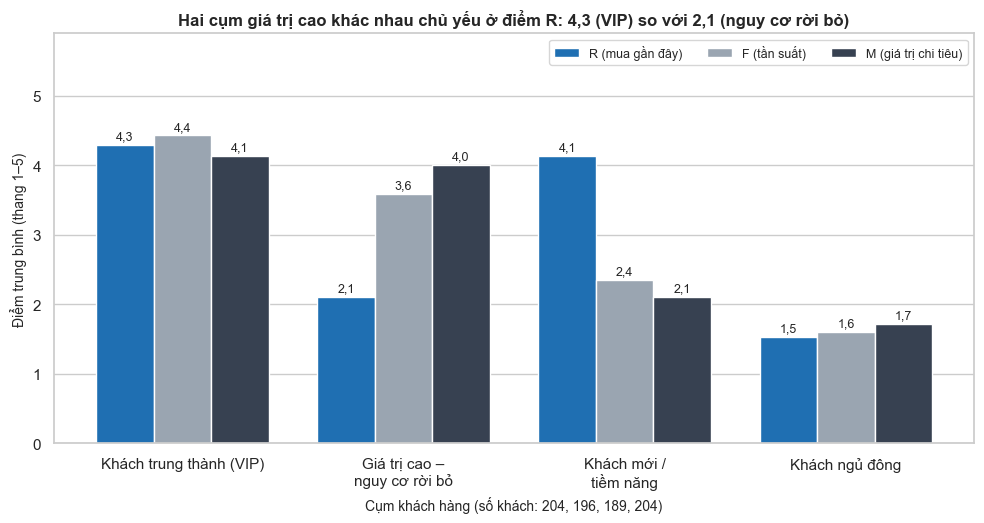

Đã lưu hình: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/figures/4_2_4_cluster_scores.png


In [14]:
nhan_hien_thi = [t.replace(" – ", " –\n").replace(" / ", " /\n") for t in ten_cum]
x = np.arange(len(ten_cum)); w = 0.26
mau = {"R": FOCUS, "F": NEUTRAL, "M": INK}
ten_diem = {"R": "R (mua gần đây)", "F": "F (tần suất)", "M": "M (giá trị chi tiêu)"}
fig, ax = plt.subplots(figsize=fs(10, 5.4))
for i, c in enumerate(["R", "F", "M"]):
    ax.bar(x + (i - 1) * w, tb[c], width=w, color=mau[c], label=ten_diem[c])
    for xi, v in zip(x + (i - 1) * w, tb[c]):
        ax.annotate(vn(v, 1), (xi, v), ha="center", va="bottom", fontsize=9, xytext=(0, 2), textcoords="offset points")
ax.set_xticks(x); ax.set_xticklabels(nhan_hien_thi)
ax.set_ylabel("Điểm trung bình (thang 1–5)"); ax.set_ylim(0, 5.9); ax.set_xlabel("Cụm khách hàng (số khách: " + ", ".join(str(int(v)) for v in tb["so_kh"]) + ")")
ax.legend(loc="upper right", ncol=3, fontsize=9)
ax.set_title(f"Hai cụm giá trị cao khác nhau chủ yếu ở điểm R: {vn(vip['R'], 1)} (VIP) so với {vn(nc['R'], 1)} (nguy cơ rời bỏ)", fontsize=12)
fig.tight_layout()
luu(fig, "4_cluster_scores")

### Bước 10. Đề xuất hành động marketing cho từng cụm

In [15]:
hanh_dong = pd.DataFrame({
    "Cụm": ten_cum,
    "Số KH": [int(tb.loc[t, "so_kh"]) for t in ten_cum],
    "Hành động đề xuất": [
        "Chương trình tri ân và ưu đãi sớm cho sản phẩm mới (không giảm giá sâu vì khách đã mua đều); mời tham gia chương trình giới thiệu bạn bè.",
        "Ưu tiên giữ chân: liên hệ cá nhân hóa, gửi ưu đãi giới hạn thời gian và nhắc mua lại các nhóm hàng họ từng mua nhiều, vì cụm này lâu chưa quay lại nhưng đóng góp lớn.",
        "Chuỗi email chào mừng và gợi ý sản phẩm bổ trợ nhằm tăng tần suất mua lần thứ hai và thứ ba; đặt mốc ưu đãi theo số đơn.",
        "Chiến dịch kích hoạt lại chi phí thấp (email, thông báo) kèm ưu đãi giới hạn; không đầu tư giảm giá lớn cho cụm này vì lợi nhuận đóng góp thấp.",
    ]})
display(hanh_dong)

,Cụm,Số KH,Hành động đề xuất
0,Khách trung thành (VIP),204,Chương trình tri ân và ưu đãi sớm cho sản phẩm...
1,Giá trị cao – nguy cơ rời bỏ,196,"Ưu tiên giữ chân: liên hệ cá nhân hóa, gửi ưu ..."
2,Khách mới / tiềm năng,189,Chuỗi email chào mừng và gợi ý sản phẩm bổ trợ...
3,Khách ngủ đông,204,"Chiến dịch kích hoạt lại chi phí thấp (email, ..."


### Bước 11. Đối chiếu với kết quả kỳ vọng

In [16]:
def gan(a, b, dung_sai): return abs(a - b) <= dung_sai

chi_dong = chi_bang.set_index("Cặp mặt hàng")["p-value"]
kiem_tra = {
    "Giỏ hàng 5.009 × 17": gio_hang.shape == (5009, 17),
    "2.346 đơn có ≥ 2 Sub-Category; trung bình 1,83": n_hai_tro_len == 2346 and gan(tb_mh, 1.83, 0.005),
    "Support cao nhất: Binders 26,3%; Paper 23,8%; Furnishings 17,5%": all(gan(sup_mh[k] * 100, v, 0.05) for k, v in {"Binders": 26.3, "Paper": 23.8, "Furnishings": 17.5}.items()),
    "Số luật lift > 1 (3%/2%/1%/0,5%/0,3%): 0/10/42/274/582": list(nguong_bang["Số luật (lift > 1)"]) == [0, 10, 42, 274, 582],
    "Apriori và FP-Growth cho cùng tập phổ biến ở mọi ngưỡng; Apriori nhanh hơn": hai_giong and ap_nhanh,
    "Ngưỡng 2%: Appliances → Binders (support 2,60%; confidence 28,8%; lift ≈ 1,10)": (luat_2.iloc[0]["antecedents"], luat_2.iloc[0]["consequents"]) == ("Appliances", "Binders")
        and gan(luat_2.iloc[0]["support"] * 100, 2.60, 0.005) and gan(luat_2.iloc[0]["confidence"] * 100, 28.8, 0.05) and gan(luat_2.iloc[0]["lift"], 1.10, 0.005),
    "Ngưỡng 1%: lift cao nhất ≈ 1,24 ({Binders, Paper} và Storage)": gan(luat_1["lift"].max(), 1.24, 0.005),
    "Ngưỡng 0,5%: {Appliances, Storage} → Binders confidence 53,6%; lift ≈ 2,04; 30 đơn": gan(luat_05.iloc[0]["confidence"] * 100, 53.6, 0.05)
        and gan(luat_05.iloc[0]["lift"], 2.04, 0.005) and luat_05.iloc[0]["so_don"] == 30,
    "Chi-square: Appliances–Binders p ≈ 0,22; Art–Phones ≈ 0,61; Furnishings–Phones ≈ 0,62": gan(chi_dong["Appliances – Binders"], 0.22, 0.005)
        and gan(chi_dong["Art – Phones"], 0.61, 0.005) and gan(chi_dong["Furnishings – Phones"], 0.62, 0.005),
    "Silhouette k = 2…7: 0,368/0,332/0,323/0,324/0,336/0,341": all(gan(sil.loc[k], v, 0.0006) for k, v in zip(range(2, 8), [0.368, 0.332, 0.323, 0.324, 0.336, 0.341])),
    "Davies–Bouldin k = 2, 3, 4: 1,102/1,131/1,090": all(gan(db.loc[k], v, 0.0006) for k, v in zip([2, 3, 4], [1.102, 1.131, 1.090])),
    "VIP: 204 KH; Recency 29 ngày; 39,8% doanh thu; 41,3% lợi nhuận": int(vip["so_kh"]) == 204 and vip["recency_tv"] == 29 and gan(vip["ty_trong_dt"], 39.8, 0.05) and gan(vip["ty_trong_ln"], 41.3, 0.05),
    "Nguy cơ rời bỏ: 196 KH; 124,5 ngày; 37,6% doanh thu; 39,4% lợi nhuận": int(nc["so_kh"]) == 196 and nc["recency_tv"] == 124.5 and gan(nc["ty_trong_dt"], 37.6, 0.05) and gan(nc["ty_trong_ln"], 39.4, 0.05),
    "Mới / tiềm năng: 189 KH; 35 ngày; 12,7% doanh thu": int(moi["so_kh"]) == 189 and moi["recency_tv"] == 35 and gan(moi["ty_trong_dt"], 12.7, 0.05),
    "Ngủ đông: 204 KH; 262,5 ngày; 9,9% doanh thu; 7,0% lợi nhuận": int(nd["so_kh"]) == 204 and nd["recency_tv"] == 262.5 and gan(nd["ty_trong_dt"], 9.9, 0.05) and gan(nd["ty_trong_ln"], 7.0, 0.05),
    "Hai cụm giá trị cao ≈ 77% doanh thu và ≈ 81% lợi nhuận": gan(hai_cum_gia_tri_dt, 77.4, 0.1) and gan(hai_cum_gia_tri_ln, 80.7, 0.1),
}
for ten, ok in kiem_tra.items():
    print("ĐẠT " if ok else "LỆCH", "–", ten)
assert all(kiem_tra.values()), "Có kết quả lệch so với kỳ vọng, cần kiểm tra lại"
print()
print("Tất cả kết quả khớp kỳ vọng.")

ĐẠT  – Giỏ hàng 5.009 × 17
ĐẠT  – 2.346 đơn có ≥ 2 Sub-Category; trung bình 1,83
ĐẠT  – Support cao nhất: Binders 26,3%; Paper 23,8%; Furnishings 17,5%
ĐẠT  – Số luật lift > 1 (3%/2%/1%/0,5%/0,3%): 0/10/42/274/582
ĐẠT  – Apriori và FP-Growth cho cùng tập phổ biến ở mọi ngưỡng; Apriori nhanh hơn
ĐẠT  – Ngưỡng 2%: Appliances → Binders (support 2,60%; confidence 28,8%; lift ≈ 1,10)
ĐẠT  – Ngưỡng 1%: lift cao nhất ≈ 1,24 ({Binders, Paper} và Storage)
ĐẠT  – Ngưỡng 0,5%: {Appliances, Storage} → Binders confidence 53,6%; lift ≈ 2,04; 30 đơn
ĐẠT  – Chi-square: Appliances–Binders p ≈ 0,22; Art–Phones ≈ 0,61; Furnishings–Phones ≈ 0,62
ĐẠT  – Silhouette k = 2…7: 0,368/0,332/0,323/0,324/0,336/0,341
ĐẠT  – Davies–Bouldin k = 2, 3, 4: 1,102/1,131/1,090
ĐẠT  – VIP: 204 KH; Recency 29 ngày; 39,8% doanh thu; 41,3% lợi nhuận
ĐẠT  – Nguy cơ rời bỏ: 196 KH; 124,5 ngày; 37,6% doanh thu; 39,4% lợi nhuận
ĐẠT  – Mới / tiềm năng: 189 KH; 35 ngày; 12,7% doanh thu
ĐẠT  – Ngủ đông: 204 KH; 262,5 ngày; 9,9% doanh